In [1]:
import glob
import numpy as np
import pandas as pd
import xarray as xr 
import seaborn as sns
import matplotlib.pyplot as plt

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)


def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf

def calculate_tercile_flags(data, var):
    # calculate terciles to cluster indices into 3 categories: -1 (negative/cold), 0 (netural), 1 (positive/warm state)
    df = data[var].to_dataframe()
    df = df.reset_index()
    df = df.set_index('time')
    tertiles = df[var].quantile([1/3, 2/3]).to_list()
    tertiles = [-float('inf')] + tertiles + [float('inf')]

    return tertiles

In [2]:
df_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nao_change.csv")
plotdir = "/home/kperny/VolMIP_stratosphere/plots/figure1/"
models = df_flags.model.unique()

In [3]:
df = df_flags.set_index(['model', 'realization'])
df['count'] = 1
# get amount of realizations of each NAO state in piControl
df_out = df.where((df['experiment']=='piControl')).dropna().drop(columns=['experiment', 'nao']).groupby(['model', 'nao_flag']).sum()
df_out = df_out.reset_index().set_index('nao_flag')
df_rel = df_out.copy()

# get amount of realizations of each NAO state in volc for the same realizations as in piControl
naon = df.where((df['experiment']=='piControl') & (df['nao_flag'] == -1)).dropna().index
naop = df.where((df['experiment']=='piControl') & (df['nao_flag'] == 1)).dropna().index
nao0 = df.where((df['experiment']=='piControl') & (df['nao_flag'] == 0)).dropna().index

states = ['NAO-', 'NAO0', 'NAO+']
for idx, value in zip([naon, naop, nao0], [-1, 1, 0]):
    volc = df.where(df['experiment']=='volc').loc[idx].dropna().drop(columns=['experiment', 'nao'])
#    df_out[state] = volc.groupby(['model', 'nao_flag']).sum()
    print(volc.groupby(['model', 'nao_flag']).sum().unstack() )
    df_out.loc[value, states] = volc.groupby(['model', 'nao_flag']).sum().unstack().values
    df_rel.loc[value, states] = volc.groupby(['model', 'nao_flag']).sum().unstack().values / df_out.reset_index().set_index(['nao_flag', 'model']).loc[value]['count'].values.reshape(5,1)
df_nao = df_out.reset_index().set_index(['nao_flag', 'model']).sort_index()
df_nao = df_nao.fillna(0)

df_rel = df_rel.reset_index().set_index(['nao_flag', 'model']).sort_index()
df_rel = df_rel.fillna(0)
# calculate relative change of NAO states in volc 
#df_rel = df_nao / df_nao['count'].values.reshape(15,1)

              count           
nao_flag       -1.0  0.0   1.0
model                         
CanESM5         6.0  1.0   6.0
GISS-E2-1-G    11.0  7.0  17.0
MIROC-ES2L      3.0  3.0   NaN
MPI-ESM1-2-LR   3.0  4.0   3.0
UKESM1-0-LL     2.0  3.0   4.0
              count            
nao_flag       -1.0   0.0   1.0
model                          
CanESM5         6.0   2.0   4.0
GISS-E2-1-G     5.0  21.0  14.0
MIROC-ES2L      4.0   3.0   4.0
MPI-ESM1-2-LR   2.0   2.0   4.0
UKESM1-0-LL     2.0   2.0   3.0
              count            
nao_flag       -1.0   0.0   1.0
model                          
CanESM5         7.0   4.0   4.0
GISS-E2-1-G    11.0  14.0  21.0
MIROC-ES2L      1.0   3.0   4.0
MPI-ESM1-2-LR   3.0   1.0   3.0
UKESM1-0-LL     2.0   3.0   4.0


In [4]:
df_pro = df_rel.copy()
df_pro[states] = df_pro[states] *100
df_pro = df_pro.round(0).apply(pd.to_numeric, downcast='integer')

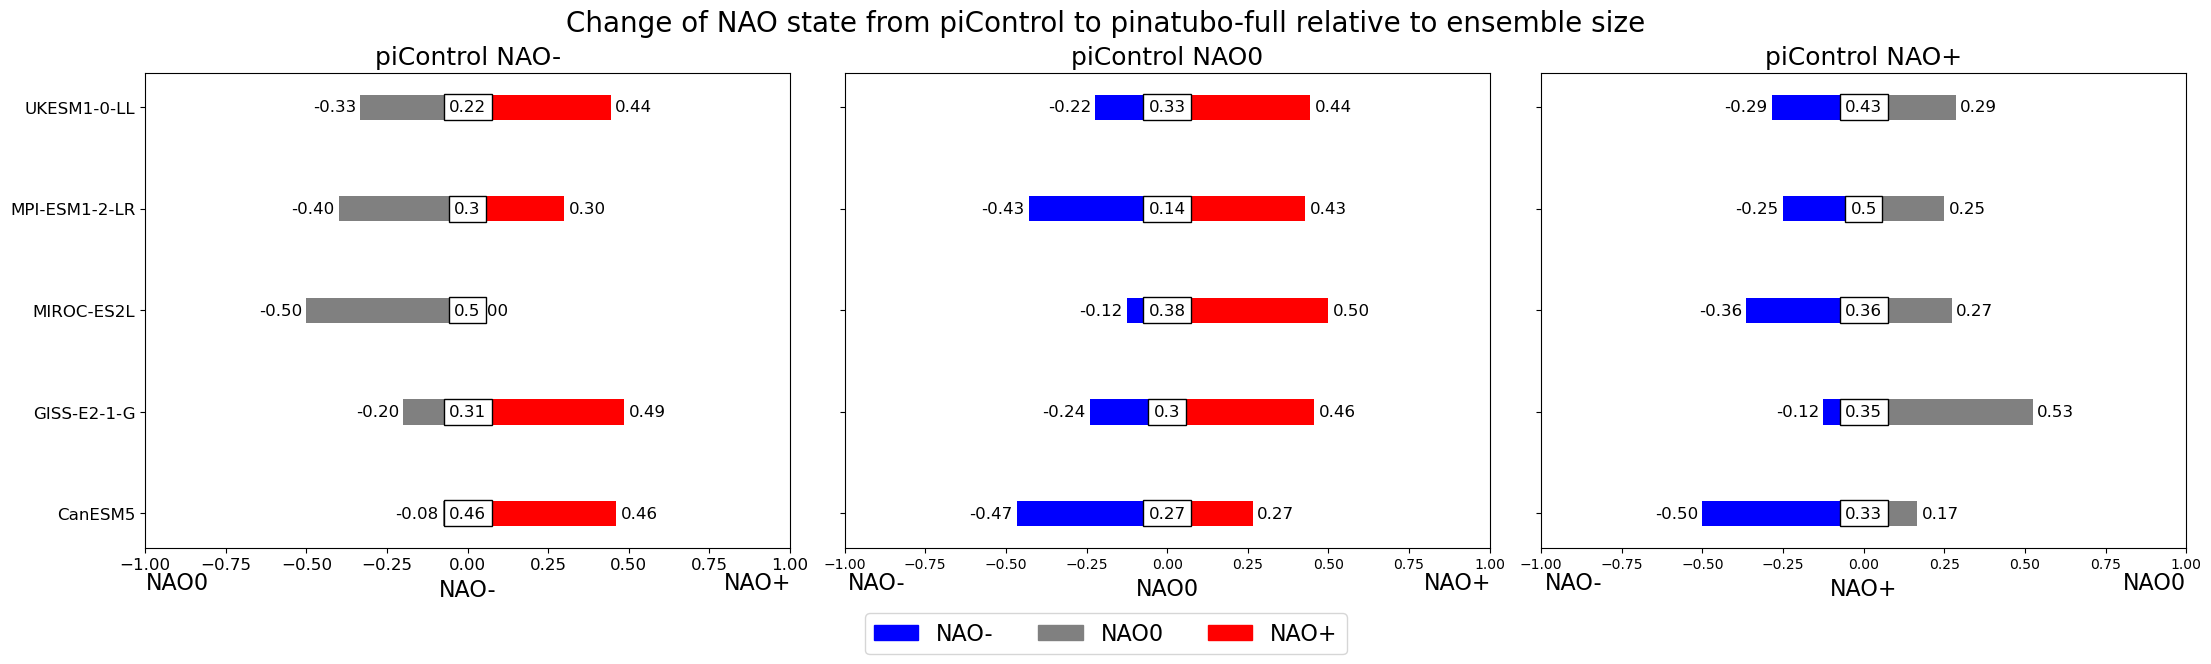

In [5]:
fig, axs = plt.subplots(1,3, figsize=(22, 6), sharey=True, layout='constrained')

data = df_rel.loc[-1].reset_index()
axs[0].barh(data['model'], data['NAO+'], height=0.25, color = 'r')
axs[0].barh(data['model'], -data['NAO0'], height=0.25, color = 'grey')

data = df_rel.loc[0].reset_index()
axs[1].barh(data['model'], -data['NAO-'], height=0.25, color = 'b')
axs[1].barh(data['model'], data['NAO+'], height=0.25, color = 'r')

data = df_rel.loc[1].reset_index()
axs[2].barh(data['model'], -data['NAO-'], height=0.25, color = 'b')
axs[2].barh(data['model'], data['NAO0'], height=0.25, color = 'grey')


for ax, nao, state, color in zip(axs, [-1,0,1], ['NAO-', 'NAO0', 'NAO+'], ['blue', 'grey', 'red']):
    ax.set_xlim(-1, 1)
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', fmt='%.2f', padding=3, fontsize=12)

    for model in models:
        # ax.annotate(df_rel.loc[nao, model][state].round(2), xy=(0, model), xycoords='data', ha='center', va='center',
        #             fontsize=12, color='white', bbox=dict(fc=color))
        ax.annotate(df_rel.loc[nao, model][state].round(2), xy=(0, model), xycoords='data', ha='center', va='center',
                    fontsize=12, color='black', bbox=dict(fc='white'))
    ax.set_xlabel(state, fontsize=16)

axs[0].set_title('piControl NAO-', fontsize=18)
axs[1].set_title('piControl NAO0', fontsize=18)
axs[2].set_title('piControl NAO+', fontsize=18)

axs[0].tick_params(axis='both', labelsize=12)

axs[0].annotate('NAO0', xy=(0.05, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAO+', xy=(0.95, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[1].annotate('NAO-', xy=(0.05, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAO+', xy=(0.95, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[2].annotate('NAO-', xy=(0.05, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAO0', xy=(0.95, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')


import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAO-')
green_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO+')
fig.legend(handles=[blue_patch, green_patch, red_patch], loc='lower center', ncol=3, fontsize=16, bbox_to_anchor=(0.5, -0.1))

plt.suptitle('Change of NAO state from piControl to pinatubo-full relative to ensemble size', fontsize=20)
plt.savefig(plotdir + 'barplot_relchange.png', dpi=200, bbox_inches='tight')

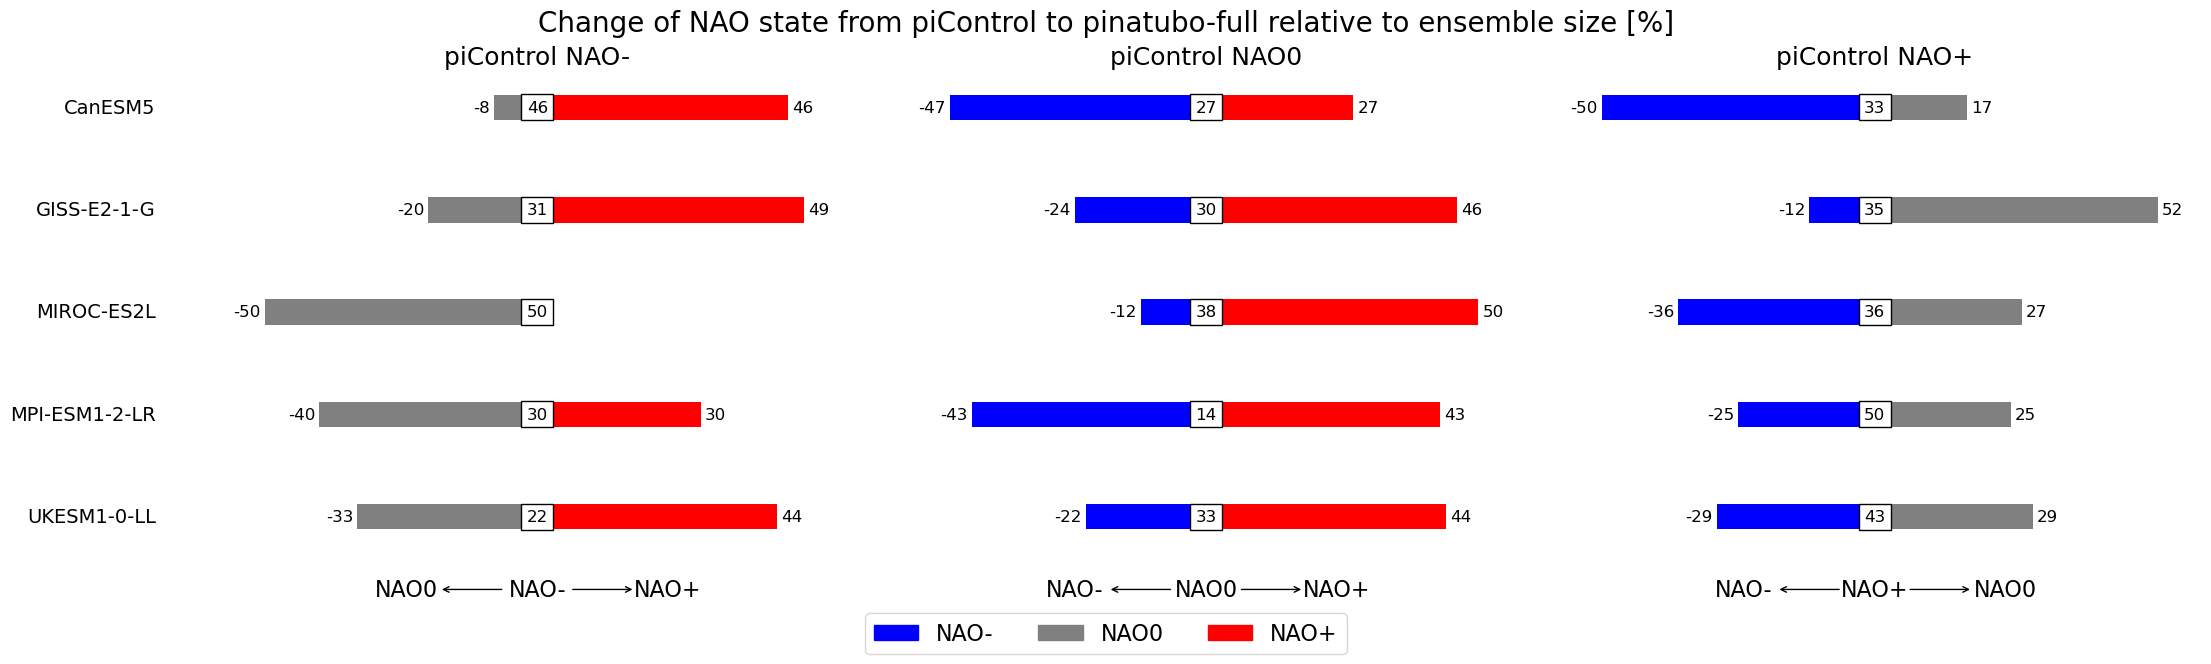

In [46]:
fig, axs = plt.subplots(1,3, figsize=(22, 6), sharey=True, layout='constrained')

data = df_pro.loc[-1].reset_index()
axs[0].barh(data['model'], data['NAO+'], height=0.25, color = 'r')
axs[0].barh(data['model'], -data['NAO0'], height=0.25, color = 'grey')

data = df_pro.loc[0].reset_index()
axs[1].barh(data['model'], -data['NAO-'], height=0.25, color = 'b')
axs[1].barh(data['model'], data['NAO+'], height=0.25, color = 'r')

data = df_pro.loc[1].reset_index()
axs[2].barh(data['model'], -data['NAO-'], height=0.25, color = 'b')
axs[2].barh(data['model'], data['NAO0'], height=0.25, color = 'grey')


for ax, nao, state, color in zip(axs, [-1,0,1], ['NAO-', 'NAO0', 'NAO+'], ['blue', 'grey', 'red']):
    ax.set_xlim(-60, 60)
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', padding=3, fontsize=12)
    for model in models:
        ax.annotate(df_pro.loc[nao, model][state], xy=(0, model), xycoords='data', ha='center', va='center',
                    fontsize=12, color='black', bbox=dict(fc='white'))
    # ax.set_xlabel(state, fontsize=16)
    ax.set_axis_off()
    ax.invert_yaxis()

    # ax.set_ylabel(data[model].values)

    ax.annotate('', xy=(0.35, -0.08), xycoords='axes fraction', xytext=(0.45, -0.08), 
            arrowprops=dict(arrowstyle="->", color='k'))
    ax.annotate('', xy=(0.55, -0.08), xycoords='axes fraction', xytext=(0.65, -0.08), 
            arrowprops=dict(arrowstyle="<-", color='k'))

# axs[0].tick_params(axis='both', labelsize=12)
    
axs[0].annotate('NAO0', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAO-', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAO+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[1].annotate('NAO-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAO0', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAO+', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[2].annotate('NAO-', xy=(0.3, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAO+', xy=(0.5, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAO0', xy=(0.7, -0.08), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

for i, model in enumerate(models):
    axs[0].annotate(model, xy=(-70,i), xycoords='data', ha='right', va='center', fontsize=14, color='k', annotation_clip=False)

axs[0].set_title('piControl NAO-', fontsize=18)
axs[1].set_title('piControl NAO0', fontsize=18)
axs[2].set_title('piControl NAO+', fontsize=18)

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAO-')
green_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO+')
fig.legend(handles=[blue_patch, green_patch, red_patch], loc='lower center', ncol=3, fontsize=16, bbox_to_anchor=(0.5, -0.1))

plt.suptitle('Change of NAO state from piControl to pinatubo-full relative to ensemble size [%]', fontsize=20)
plt.savefig(plotdir + 'barplot_relchange_percent.png', dpi=200, bbox_inches='tight')

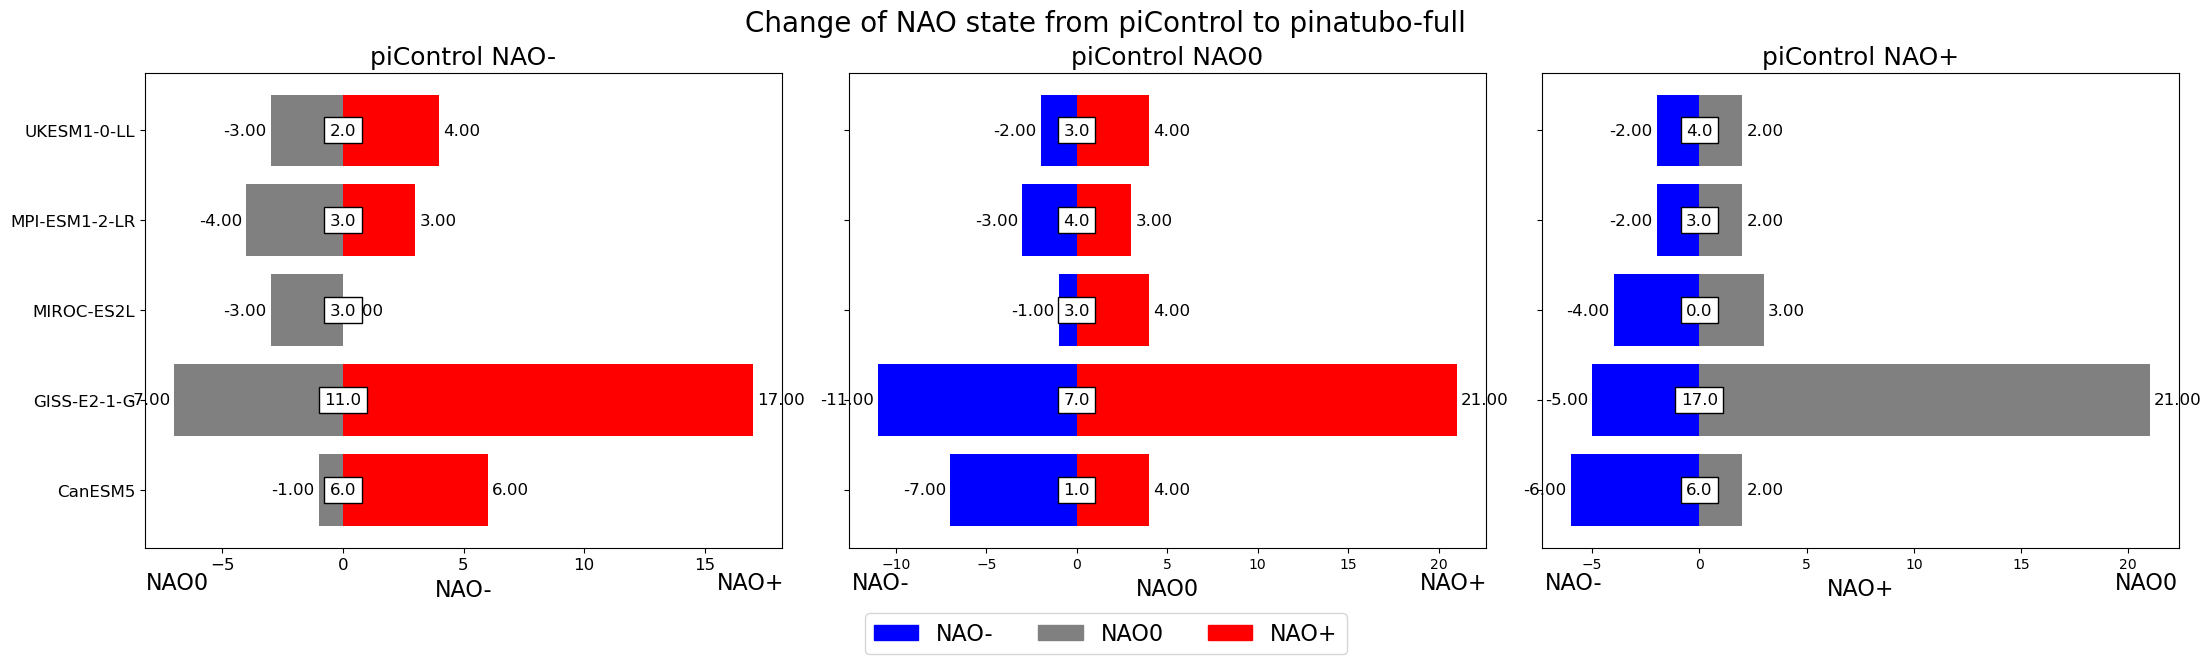

In [47]:
fig, axs = plt.subplots(1,3, figsize=(22, 6), sharey=True, layout='constrained')

data = df_nao.loc[-1].reset_index()
axs[0].barh(data['model'], data['NAO+'], color = 'r')
axs[0].barh(data['model'], -data['NAO0'], color = 'grey')

data = df_nao.loc[0].reset_index()
axs[1].barh(data['model'], -data['NAO-'], color = 'b')
axs[1].barh(data['model'], data['NAO+'], color = 'r')

data = df_nao.loc[1].reset_index()
axs[2].barh(data['model'], -data['NAO-'], color = 'b')
axs[2].barh(data['model'], data['NAO0'], color = 'grey')

for ax, nao, state  in zip(axs, [-1,0,1], ['NAO-', 'NAO0', 'NAO+']):
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', fmt='%.2f', padding=3, fontsize=12)

    for model in models:
        ax.annotate(df_nao.loc[-1, model][state].round(2), xy=(0, model), xycoords='data', ha='center', va='center',
                    fontsize=12, color='black', bbox=dict(fc='white'))
    ax.set_xlabel(state, fontsize=16)

axs[0].set_title('piControl NAO-', fontsize=18)
axs[1].set_title('piControl NAO0', fontsize=18)
axs[2].set_title('piControl NAO+', fontsize=18)

axs[0].tick_params(axis='both', labelsize=12)

axs[0].annotate('NAO0', xy=(0.05, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[0].annotate('NAO+', xy=(0.95, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[1].annotate('NAO-', xy=(0.05, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[1].annotate('NAO+', xy=(0.95, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

axs[2].annotate('NAO-', xy=(0.05, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')
axs[2].annotate('NAO0', xy=(0.95, -0.075), xycoords='axes fraction', ha='center', va='center', fontsize=16, color='k')

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='NAO-')
grey_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO+')
fig.legend(handles=[blue_patch, grey_patch, red_patch], loc='lower center', ncol=3, fontsize=16, bbox_to_anchor=(0.5, -0.1))

plt.suptitle('Change of NAO state from piControl to pinatubo-full', fontsize=20)
plt.savefig(plotdir + 'barplot_abschange.png', dpi=200, bbox_inches='tight')